# 03 — Spectral clustering of the product graph

Can purchase behaviour alone recover how the supermarket is organised? We turn the frequent pairs of notebook 02 into a
weighted **product graph** and cluster it with our own spectral clustering.

1. A toy graph that can be checked by hand, and checks against scikit-learn and networkx
2. The product graph: nodes, edges, weights and connected components
3. The spectrum: eigenvalues, the eigengap, and dense vs. sparse eigen-solvers
4. The lecture's bipartition with the Fiedler vector
5. Design choices: edge weights and sparsification
6. Choosing the number of clusters $k$
7. Comparing methods: normalised vs. unnormalised Laplacian, recursive bipartition, scikit-learn, Louvain
8. What the clusters contain, and how they relate to the real departments and aisles

Needs only `data/derived/rules_support_1e-4.csv` (notebook 02) and `products.csv`, `aisles.csv`, `departments.csv`.
About 3 minutes.

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score

sys.path.insert(0, str(Path.cwd().parent))
from src.data import DATA_DIR
from src.spectral import (product_graph, keep_top_neighbours, components, subgraph, laplacian, smallest_eigenpairs,
                          eigengap, fiedler_split, spectral_clustering, recursive_bipartition, kmeans,
                          modularity, normalised_cut, cluster_table, WEIGHTS)

ROOT = Path.cwd().parent
FIG_DIR, DERIVED = ROOT / "figures", ROOT / "data" / "derived"
FIG_DIR.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
BLUES = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "lines.linewidth": 2})
pd.set_option("display.max_colwidth", 120)

## 1. A toy graph that can be checked by hand

The graph of exercise 3 of week 7: three triangles joined by three edges. Its Laplacian $L = D - A$ has
$\lambda_1 = 0$ (eigenvector $(1,\dots,1)$) and a **double** $\lambda_2 = \lambda_3 \approx 0.697$, because the graph is
symmetric: any of the three triangles could be the one split off. Clustering into $k=3$ must return the three triangles.

In [2]:
G = nx.Graph([(0, 1), (0, 2), (1, 2), (3, 4), (3, 5), (4, 5), (6, 7), (6, 8), (7, 8), (1, 3), (2, 6), (5, 7)])
A = sp.csr_matrix(nx.to_numpy_array(G, nodelist=range(9)))
triangles = np.repeat([0, 1, 2], 3)

print("L = D - A:\n", laplacian(A, "unnormalized").toarray().astype(int))
for kind in ("unnormalized", "sym"):
    dense, _ = smallest_eigenpairs(A, 9, kind, "dense")
    sparse, _ = smallest_eigenpairs(A, 4, kind, "sparse")
    assert np.allclose(dense[:4], sparse), "dense and sparse solvers must agree"
    print(f"{kind:13s} eigenvalues:", dense.round(4))

X, lam2, x2 = fiedler_split(A)
print("\nFiedler vector x2:", x2.round(3), f"(lambda_2 = {lam2:.4f})")
print("bipartition by sign:  X =", np.flatnonzero(X).tolist(), " Y =", np.flatnonzero(~X).tolist())

ours = spectral_clustering(A, 3)
rec = recursive_bipartition(A, 3, "unnormalized")
assert adjusted_rand_score(triangles, ours) == 1 and adjusted_rand_score(triangles, rec) == 1
communities = [set(np.flatnonzero(ours == c)) for c in range(3)]
assert np.isclose(modularity(A, ours), nx.community.modularity(G, communities))
print(f"k = 3: both methods return exactly the three triangles; modularity {modularity(A, ours):.4f} (= networkx)")

L = D - A:
 [[ 2 -1 -1  0  0  0  0  0  0]
 [-1  3 -1 -1  0  0  0  0  0]
 [-1 -1  3  0  0  0 -1  0  0]
 [ 0 -1  0  3 -1 -1  0  0  0]
 [ 0  0  0 -1  2 -1  0  0  0]
 [ 0  0  0 -1 -1  3  0 -1  0]
 [ 0  0 -1  0  0  0  3 -1 -1]
 [ 0  0  0  0  0 -1 -1  3 -1]
 [ 0  0  0  0  0  0 -1 -1  2]]
unnormalized  eigenvalues: [0.     0.6972 0.6972 3.     3.     3.     4.3028 4.3028 5.    ]
sym           eigenvalues: [0.     0.2779 0.2779 1.1299 1.1299 1.3333 1.5921 1.5921 1.6667]

Fiedler vector x2: [-0.227 -0.039 -0.257  0.395  0.583  0.365 -0.326 -0.137 -0.356] (lambda_2 = 0.6972)
bipartition by sign:  X = [0, 1, 2, 6, 7, 8]  Y = [3, 4, 5]
k = 3: both methods return exactly the three triangles; modularity 0.4167 (= networkx)


**A pitfall of the sign rule.** Because $\lambda_2 = \lambda_3$, any combination of the two eigenvectors is a valid $x_2$.
With $L_{sym}$ the solver returns one in which node 6 gets $x_6 \approx 0$, so the sign rule puts it with the top
triangle instead of its own and a triangle is broken. The lecture's alternative, 2-means on the entries of $x_2$ (in one dimension the
optimal threshold can be found exactly by trying every gap), puts it back.

In [3]:
for split in ("sign", "kmeans"):
    X, _, x2 = fiedler_split(A, "sym", split=split)
    rec = recursive_bipartition(A, 3, "sym", split)
    print(f"L_sym, split by {split:6s}: x2 = {x2.round(2)}  first split X = {np.flatnonzero(X).tolist()}  k=3: {rec}")

L_sym, split by sign  : x2 = [ 0.34  0.23  0.26 -0.11 -0.23 -0.23  0.   -0.16 -0.11]  first split X = [3, 4, 5, 7, 8]  k=3: [0 0 0 1 1 1 0 2 2]
L_sym, split by kmeans: x2 = [ 0.34  0.23  0.26 -0.11 -0.23 -0.23  0.   -0.16 -0.11]  first split X = [3, 4, 5, 6, 7, 8]  k=3: [0 0 0 1 1 1 2 2 2]


**Check against scikit-learn on a real network.** On Zachary's karate club our clustering (normalised Laplacian, rows
scaled to unit length, own k-means) should agree with `SpectralClustering(affinity="precomputed")`, which uses the same idea.

In [4]:
K = nx.karate_club_graph()
AK = sp.csr_matrix(nx.to_numpy_array(K, weight=None))
rows = []
for k in (2, 3, 4):
    ours = spectral_clustering(AK, k)
    theirs = SpectralClustering(n_clusters=k, affinity="precomputed", random_state=0).fit_predict(AK.toarray())
    rows.append({"k": k, "ARI ours vs sklearn": adjusted_rand_score(ours, theirs),
                 "modularity ours": modularity(AK, ours), "modularity sklearn": modularity(AK, theirs)})
pd.DataFrame(rows).round(4)

,k,ARI ours vs sklearn,modularity ours,modularity sklearn
0,2,1.0000,0.3600,0.3600
1,3,1.0000,0.3991,0.3991
2,4,0.9269,0.4198,0.4102


## 2. The product graph

One node per product, one edge per frequent pair $\{a, b\}$ from notebook 02 (support $\ge 10^{-4}$, i.e. at least 321 of the
3.2M baskets) whose **lift** is above 1, i.e. the two are bought together more often than if they were independent.
The weight of the edge says how strongly. Lift is very skewed, so we start with $\log(\text{lift})$ (Section 5 compares the alternatives).

In [5]:
rules = pd.read_csv(DERIVED / "rules_support_1e-4.csv")
products = (pd.read_csv(DATA_DIR / "products.csv")
            .merge(pd.read_csv(DATA_DIR / "aisles.csv"), on="aisle_id")
            .merge(pd.read_csv(DATA_DIR / "departments.csv"), on="department_id"))
info = products.set_index("product_id")

pairs = rules[rules["antecedent"] < rules["consequent"]]
print(f"{len(pairs):,} frequent pairs, {(pairs['lift'] > 1).sum():,} with lift > 1")
print("lift percentiles 10/50/90/99%:", pairs["lift"].quantile([.1, .5, .9, .99]).round(1).tolist())

W_all, ids_all = product_graph(rules, "log_lift")
comp = components(W_all)
sizes = np.bincount(comp)
print(f"\ngraph: {W_all.shape[0]:,} products, {W_all.nnz // 2:,} edges, {len(sizes)} connected components")
print(f"largest component: {sizes[0]:,} products; the other {len(sizes) - 1} have {sizes[1:].min()}-{sizes[1:].max()} products")

57,035 frequent pairs, 54,733 with lift > 1
lift percentiles 10/50/90/99%: [1.2, 1.9, 4.0, 127.3]

graph: 3,687 products, 54,733 edges, 22 connected components
largest component: 3,634 products; the other 21 have 2-5 products


**The small components.** Every connected component gives its own zero eigenvalue, so 22 components would use up the
first 22 eigenvectors just to separate them. We therefore cluster only the largest component and report the small
ones as they are: almost all are one brand's product line.

In [6]:
pd.DataFrame([{"products": int((comp == c).sum()),
               "department": info.loc[ids_all[comp == c], "department"].mode()[0],
               "examples": "; ".join(info.loc[ids_all[comp == c], "product_name"].iloc[:3])}
              for c in range(1, len(sizes))])

,products,department,examples
0,5,beverages,Orange Mango Sparkling Water; Classic Lemonade; Pink Grapefruit
1,4,pets,Grain Free Chicken Formula Cat Food; Grain Free Turkey & Salmon Formula Cat Food; Grain Free Turkey Formula Cat Food
2,3,beverages,Yerba Mate Sparkling Classic Gold; Organic Grapefruit Ginger Sparkling Yerba Mate; Cranberry Pomegranate Sparkling Y...
3,3,snacks,Coconut Kale & Cacao Organic Superfoods Bar; Organic Turmeric Ginger & Beet Superfoods Bar; Organic Hazelnut Hemp Ca...
4,3,beverages,Wild Berry Sparkling Energy Water; Sparkling Energy Water Lemon Lime; Grapefruit Sparkling Energy Water
5,3,babies,Carrot Squash & Apple 100% Vegetable & Fruit Puree; Peter Rabbit Organics Kale Broccoli and Mango Purée; Peter Rabbi...
6,3,dairy eggs,Blueberry Soy Yogurt; Dairy Free Soy Strawberry Alternative; Peach & Mango Soy Yogurt
7,3,dairy eggs,O'Soy Fruit on the Bottom Strawberry Organic Soy Yogurt; O'Soy Smooth & Creamy Vanilla Organic Soy Yogurt; O'Soy Fru...
8,2,dairy eggs,"Yogurt, Sheep Milk, Strawberry; Yogurt, Sheep Milk, Blackberry"
9,2,dairy eggs,Organic Raspberry Yogurt; Organic Wildberry Yogurt


## 3. The spectrum

We use the normalised Laplacian $L_{sym} = I - D^{-1/2} W D^{-1/2}$ (lecture: "with more eigenvectors, use a normalised
Laplacian"). Its eigenvalues lie in $[0, 2]$. A dense solver (`numpy.linalg.eigh`) computes all $n$ eigenpairs in
$O(n^3)$; the sparse Lanczos solver (`scipy.sparse.linalg.eigsh`) computes only the few we need from sparse
matrix-vector products. Both must give the same eigenvalues.

In [7]:
W_raw, ids = subgraph(W_all, ids_all, comp == 0)
N_EIG = 150
t = time.time(); vals, _ = smallest_eigenpairs(W_raw, N_EIG, "sym", "sparse"); t_sparse = time.time() - t
t = time.time(); vals_dense, _ = smallest_eigenpairs(W_raw, N_EIG, "sym", "dense"); t_dense = time.time() - t
assert np.allclose(vals, vals_dense, atol=1e-8)
print(f"{W_raw.shape[0]:,} nodes, {W_raw.nnz // 2:,} edges, density {W_raw.nnz / W_raw.shape[0] ** 2:.2%}")
print(f"{N_EIG} smallest eigenpairs: sparse eigsh {t_sparse:.1f}s, dense eigh {t_dense:.1f}s, max difference {np.abs(vals - vals_dense).max():.1e}")
print("smallest eigenvalues:", vals[:10].round(4))

3,634 nodes, 54,698 edges, density 0.83%
150 smallest eigenpairs: sparse eigsh 0.8s, dense eigh 6.0s, max difference 6.7e-15
smallest eigenvalues: [0.     0.001  0.0047 0.0059 0.0076 0.008  0.012  0.0144 0.0151 0.016 ]


**Scaling.** The dense solver's time grows with $n^3$ and its memory with $n^2$, so for larger graphs (lower support,
more products) only the sparse solver is usable. We time both on growing subgraphs (the $n$ most connected products).

In [8]:
order = np.argsort(-np.asarray(W_raw.sum(1)).ravel())
rows = []
for n in (500, 1000, 2000, W_raw.shape[0]):
    S = W_raw[order[:n]][:, order[:n]]
    keep = components(S) == 0
    S = S[keep][:, keep]
    row = {"nodes": S.shape[0]}
    for solver in ("dense", "sparse"):
        t = time.time(); smallest_eigenpairs(S, 50, "sym", solver); row[f"{solver} s"] = round(time.time() - t, 2)
    rows.append(row)
pd.DataFrame(rows)

,nodes,dense s,sparse s
0,500,0.03,0.03
1,998,0.17,0.03
2,2000,1.11,0.15
3,3634,5.96,0.27


## 4. The lecture's bipartition (Fiedler vector)

Split the largest component by the sign of the eigenvector of $\lambda_2$, once with the unnormalised Laplacian
$L = D - W$ (the lecture's version) and once with the normalised $L_{sym}$ (for $L_{sym}$ we split the sign of
$D^{-1/2}$ times the eigenvector, which has the same signs).

In [9]:
for kind in ("unnormalized", "sym"):
    X, lam2, x2 = fiedler_split(W_raw, kind)
    small = X if X.sum() < (~X).sum() else ~X
    print(f"{kind:13s} lambda_2 = {lam2:.4f}: sides of {small.sum()} and {(~small).sum()} products; "
          f"small side: " + "; ".join(info.loc[ids[small], "product_name"].iloc[:5]))

unnormalized  lambda_2 = 0.0009: sides of 1 and 3633 products; small side: Diet Peach Tea


sym           lambda_2 = 0.0010: sides of 9 and 3625 products; small side: Sauvignon Blanc; Pinot Noir; Amber Ale; Cabernet Sauvignon; Chardonnay


Neither split is balanced. The unnormalised Laplacian (which approximates RatioCut, $|E(A,B)|/|A| + |E(A,B)|/|B|$) cuts
off a single product that hangs on the graph by weak edges, the problem the lecture shows for the minimum cut.
The normalised Laplacian (which approximates the normalised cut, dividing by vol instead of size) cuts off a small but
meaningful group: the wines and beers, which are bought together but rarely with groceries.
A single eigenvector is therefore not enough on this graph; we need $k$ eigenvectors (Section 6) or a recursive
split that keeps splitting the large part (Section 7).

## 5. Design choices: edge weights and sparsification

Two choices shape the graph before any clustering:

- **Weight**: `binary` (every frequent pair is an edge of weight 1), `count` (baskets containing both), `lift`, or `log_lift`.
- **Sparsification**: popular products such as bananas have edges to almost everything, mostly with lift just above 1.
  Keeping only each product's $m$ strongest edges (an edge survives if it is in the top $m$ of either end) removes those weak hub edges.

We compare them at a fixed $k = 50$ with **unsupervised** criteria only (modularity, normalised cut, and the size of the
largest cluster): the department and aisle labels are kept for the final evaluation and are not used to choose the graph.

In [10]:
def largest_component(W, ids):
    c = components(W)
    return subgraph(W, ids, c == 0)

K_DESIGN = 50
rows, graphs = [], {}
for weight in WEIGHTS:
    W_w, ids_w = product_graph(rules, weight)
    for m in (None, 20, 10, 5):
        W, ids_g = largest_component(W_w if m is None else keep_top_neighbours(W_w, m), ids_w)
        graphs[(weight, m)] = (W, ids_g)
        labels = spectral_clustering(W, K_DESIGN)
        rows.append({"weight": weight, "top m": "all" if m is None else m, "nodes": W.shape[0], "edges": W.nnz // 2,
                     "modularity": modularity(W, labels), "Ncut / k": normalised_cut(W, labels) / K_DESIGN,
                     "largest cluster": f"{np.bincount(labels).max() / W.shape[0]:.0%}"})
design = pd.DataFrame(rows)
design.round(3)

,weight,top m,nodes,edges,modularity,Ncut / k,largest cluster
0,binary,all,3634,54698,0.166,0.541,18%
1,binary,20,3634,26960,0.216,0.548,21%
2,binary,10,3634,18585,0.225,0.558,19%
3,binary,5,3634,12114,0.307,0.531,19%
4,count,all,3634,54698,0.100,0.495,19%
5,count,20,3634,27542,0.111,0.474,19%
6,count,10,3634,18730,0.157,0.425,27%
7,count,5,3623,12106,0.126,0.359,32%
8,lift,all,3634,54698,0.618,0.026,50%
9,lift,20,3634,24263,0.808,0.023,44%


Modularity is only comparable between clusterings **of the same graph**, so it is compared within each block of rows.

- Raw `lift` reaches by far the highest modularity, but by cutting off tiny groups of niche products with enormous lifts
  (two flavours of one brand) while one cluster keeps 28-50% of all products.
- `binary` and `count` ignore how surprising a pair is; `count` is dominated by the popular products, so their clusterings
  have the lowest modularity.
- `log_lift` keeps the ordering of lift but damps its extremes; no cluster gets more than about 20% of the products.
- Sparsifying raises modularity for every weight. With $m = 5$, 33 products fall off the largest component, while $m = 10$
  keeps all 3,634 products with a third of the edges.

We continue with **log-lift, top 10 neighbours**.

In [11]:
WEIGHT, TOP_M = "log_lift", 10
W, ids = graphs[(WEIGHT, TOP_M)]
dept = info.loc[ids, "department"].to_numpy()
aisle = info.loc[ids, "aisle"].to_numpy()
print(f"chosen graph: {W.shape[0]:,} products, {W.nnz // 2:,} edges, "
      f"{len(np.unique(dept))} departments and {len(np.unique(aisle))} aisles among them")

chosen graph: 3,634 products, 16,583 edges, 20 departments and 115 aisles among them


## 6. Choosing the number of clusters $k$

Two unsupervised guides: the **eigengap** (a large jump $\lambda_{k+1} - \lambda_k$ means the graph is close to having
$k$ separate parts) and **modularity** as a function of $k$.

For the comparison with the real categories we also report how well the clusters match the 21 departments and the
134 aisles. NMI (normalised mutual information) rises with $k$ even for random labels, so we use
**AMI** (adjusted mutual information), which subtracts the value expected by chance: 0 for random, 1 for identical.
To make this visible we also score a random permutation of our labels.

In [12]:
vals, _ = smallest_eigenpairs(W, N_EIG, "sym", "sparse")
k_gap, gaps = eigengap(vals, k_min=10)
print(f"eigengap suggests k = {k_gap}; largest gaps at k =", (np.argsort(-gaps[9:])[:5] + 10).tolist())

rng = np.random.default_rng(0)
rows = []
for k in (10, 21, 30, 50, 75, 100, 134):
    labels = spectral_clustering(W, k)
    shuffled = rng.permutation(labels)
    rows.append({"k": k, "modularity": modularity(W, labels), "Ncut / k": normalised_cut(W, labels) / k,
                 "NMI dept": normalized_mutual_info_score(dept, labels), "NMI dept (random)": normalized_mutual_info_score(dept, shuffled),
                 "AMI dept": adjusted_mutual_info_score(dept, labels), "AMI aisle": adjusted_mutual_info_score(aisle, labels),
                 "AMI aisle (random)": adjusted_mutual_info_score(aisle, shuffled), "ARI dept": adjusted_rand_score(dept, labels)})
by_k = pd.DataFrame(rows)
by_k.round(3)

eigengap suggests k = 131; largest gaps at k = [131, 90, 127, 55, 136]


,k,modularity,Ncut / k,NMI dept,NMI dept (random),AMI dept,AMI aisle,AMI aisle (random),ARI dept
0,10,0.056,0.007,0.036,0.013,0.026,0.016,0.001,0.002
1,21,0.572,0.107,0.104,0.019,0.087,0.102,-0.001,0.010
2,30,0.583,0.209,0.127,0.026,0.104,0.114,-0.000,0.017
3,50,0.590,0.181,0.170,0.037,0.137,0.144,-0.002,0.023
4,75,0.571,0.246,0.186,0.051,0.143,0.156,0.002,0.021
5,100,0.555,0.277,0.211,0.064,0.159,0.170,0.001,0.013
6,134,0.541,0.326,0.242,0.080,0.176,0.179,0.002,0.007


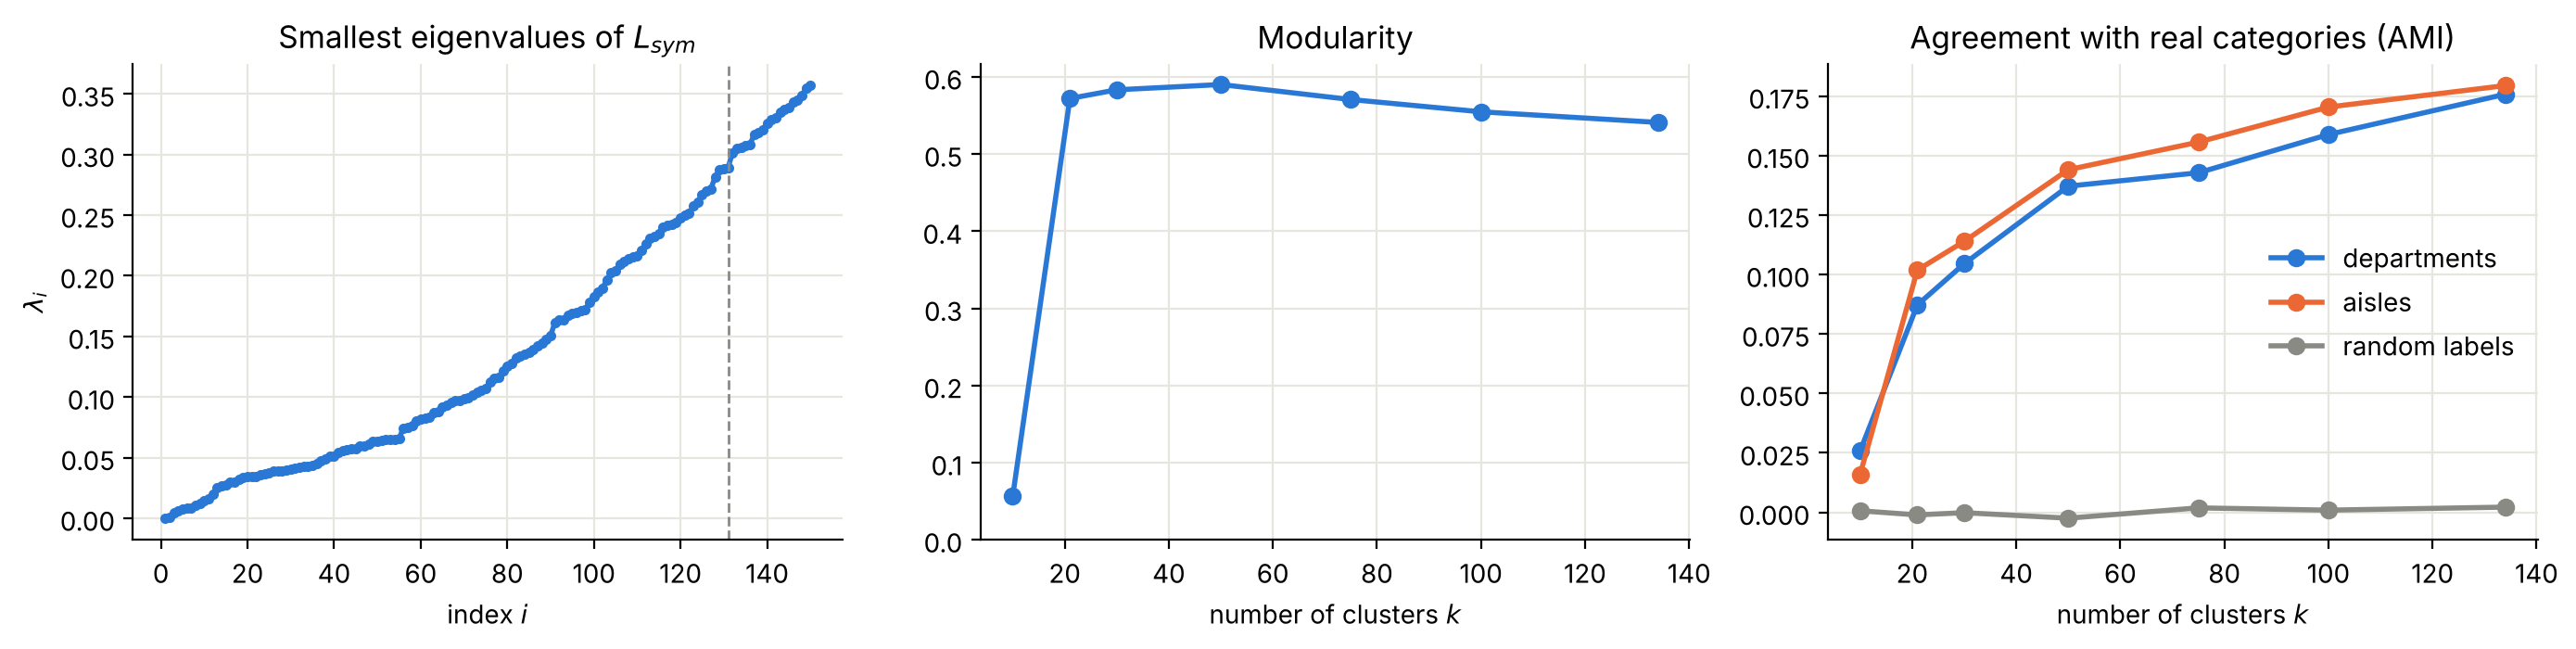

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(np.arange(1, N_EIG + 1), vals, color=BLUE, marker="o", markersize=3)
ax[0].axvline(k_gap, color=GREY, linestyle="--", linewidth=1)
ax[0].set(title="Smallest eigenvalues of $L_{sym}$", xlabel="index $i$", ylabel=r"$\lambda_i$")
ax[1].plot(by_k["k"], by_k["modularity"], color=BLUE, marker="o")
ax[1].set(title="Modularity", xlabel="number of clusters $k$", ylim=(0, None))
for col, color, label in (("AMI dept", BLUE, "departments"), ("AMI aisle", ORANGE, "aisles"), ("AMI aisle (random)", GREY, "random labels")):
    ax[2].plot(by_k["k"], by_k[col], color=color, marker="o", label=label)
ax[2].set(title="Agreement with real categories (AMI)", xlabel="number of clusters $k$")
ax[2].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "spectral_choose_k.png", dpi=150)

In [14]:
K_FINAL = int(by_k.loc[by_k["modularity"].idxmax(), "k"])
print(f"k with the highest modularity: {K_FINAL}")

k with the highest modularity: 50


## 7. Comparing methods at the chosen $k$

- **NJW**: normalised Laplacian, rows scaled to unit length, k-means (our main method)
- **unnormalised**: $L = D - W$, k-means on the raw eigenvector rows
- **recursive bipartition**: the lecture's "idea 1", repeatedly splitting the largest cluster by its Fiedler vector,
  with the unnormalised and the normalised Laplacian, and with the sign rule or the 1-D 2-means threshold
- **scikit-learn** `SpectralClustering` on the same graph, as a reference implementation
- **Louvain** (networkx) on the same graph, which optimises modularity directly and chooses its own number of communities;
  for a fair comparison NJW is also run with Louvain's number of communities

In [15]:
def score(name, labels, seconds):
    return {"method": name, "clusters": len(np.unique(labels)), "seconds": round(seconds, 1),
            "modularity": modularity(W, labels), "Ncut / k": normalised_cut(W, labels) / len(np.unique(labels)),
            "largest cluster": np.bincount(labels).max(), "AMI dept": adjusted_mutual_info_score(dept, labels),
            "AMI aisle": adjusted_mutual_info_score(aisle, labels), "ARI aisle": adjusted_rand_score(aisle, labels)}

results, labels_of = [], {}
runs = {
    "NJW (own)": lambda: spectral_clustering(W, K_FINAL, "sym"),
    "unnormalised (own)": lambda: spectral_clustering(W, K_FINAL, "unnormalized"),
    "recursive, L, sign (own)": lambda: recursive_bipartition(W, K_FINAL, "unnormalized", "sign"),
    "recursive, L_sym, sign (own)": lambda: recursive_bipartition(W, K_FINAL, "sym", "sign"),
    "recursive, L_sym, 2-means (own)": lambda: recursive_bipartition(W, K_FINAL, "sym", "kmeans"),
    "scikit-learn": lambda: SpectralClustering(K_FINAL, affinity="precomputed", random_state=0).fit_predict(W),
}
for name, run in runs.items():
    t = time.time(); labels_of[name] = run(); results.append(score(name, labels_of[name], time.time() - t))

t = time.time()
louvain = nx.community.louvain_communities(nx.from_scipy_sparse_array(W), weight="weight", seed=0)
labels_of["Louvain"] = np.zeros(W.shape[0], dtype=int)
for c, members in enumerate(louvain):
    labels_of["Louvain"][list(members)] = c
results.append(score("Louvain (networkx)", labels_of["Louvain"], time.time() - t))
k_louvain = len(louvain)
t = time.time(); labels_of["NJW at Louvain's k"] = spectral_clustering(W, k_louvain)
results.append(score(f"NJW (own), k = {k_louvain}", labels_of["NJW at Louvain's k"], time.time() - t))
methods = pd.DataFrame(results)
print(f"ARI between our NJW and scikit-learn: {adjusted_rand_score(labels_of['NJW (own)'], labels_of['scikit-learn']):.3f}")
methods.round(3)

ARI between our NJW and scikit-learn: 0.075


,method,clusters,seconds,modularity,Ncut / k,largest cluster,AMI dept,AMI aisle,ARI aisle
0,NJW (own),50,1.0,0.590,0.181,711,0.137,0.144,0.023
1,unnormalised (own),50,0.5,0.012,0.841,3566,0.020,0.010,0.001
2,"recursive, L, sign (own)",50,6.8,0.038,0.845,3317,0.027,0.018,0.002
3,"recursive, L_sym, sign (own)",50,2.4,0.564,0.222,451,0.124,0.145,0.050
4,"recursive, L_sym, 2-means (own)",50,3.6,0.469,0.044,3088,0.122,0.096,-0.001
5,scikit-learn,50,0.4,0.445,0.039,3143,0.117,0.090,-0.002
6,Louvain (networkx),68,0.2,0.687,0.081,1662,0.155,0.163,0.005
7,"NJW (own), k = 68",68,1.6,0.570,0.221,662,0.144,0.153,0.028


## 8. What the clusters contain

For every cluster: its size, its most common department and aisle (with their share of the cluster), and the products
with the most and strongest connections. Clusters are numbered from largest to smallest.

In [16]:
labels = labels_of["NJW (own)"]
table = cluster_table(labels, ids, products, W)
table["purity (dept)"] = [pd.Series(dept[labels == c]).value_counts(normalize=True).iloc[0] for c in table["cluster"]]
table.head(15)

,cluster,size,top department,top aisle,examples,purity (dept)
0,0,711,dairy eggs (18%),packaged cheese (5%),"Banana; 0% Greek, Blueberry on the Bottom Yogurt; Nonfat Strawberry With Fruit On The Bottom Greek Yogurt; Light Str...",0.175809
1,1,601,snacks (17%),bread (5%),Organic Strawberries; Organic Hass Avocado; Organic Whole Milk; Organic Greek Whole Milk Blended Strawberry Yogurt; ...,0.166389
2,2,385,produce (47%),fresh vegetables (31%),Organic Garlic; Organic Italian Parsley Bunch; Yellow Onions; Organic Cilantro; Grated Parmesan,0.467532
3,3,368,dairy eggs (18%),yogurt (7%),Organic Baby Spinach; Organic Raspberries; Organic Avocado; YoKids Squeeze! Organic Strawberry Flavor Yogurt; Bluebe...,0.182065
4,4,351,dairy eggs (21%),fresh fruits (9%),Limes; Organic Whole String Cheese; Large Lemon; Organic Yellow Onion; Organic Zucchini,0.213675
5,5,256,dairy eggs (16%),refrigerated (5%),Bag of Organic Bananas; Whole Wheat Blueberry Fig Bars; Just Sweet Potato Baby Food; Stage 1 Just Butternut Squash B...,0.156250
6,6,135,produce (34%),packaged produce (16%),Clementines; Trail Mix; Hass Avocados; Soda; 0% Greek Strained Yogurt,0.340741
7,7,101,produce (33%),fresh fruits (15%),100% Whole Wheat Bread; Fresh CA Grown Eggs; Blueberries; Small Hass Avocado; Bartlett Pears,0.326733
8,8,75,produce (20%),packaged vegetables fruits (12%),Steamfresh Sweet Peas; Organic Apple Slices; Naked Green Machine Boosted Juice Smoothie; Steamfresh Super Sweet Corn...,0.200000
9,9,67,snacks (49%),chips pretzels (24%),Organic Reduced Fat 2% Milk; Half & Half; Unsweetened Almondmilk; Sea Salt & Vinegar Potato Chips; Peanut Butter Bar,0.492537


In [17]:
print("The purest clusters (by department share, at least 10 products):")
table[table["size"] >= 10].sort_values("purity (dept)", ascending=False).head(10)

The purest clusters (by department share, at least 10 products):


,cluster,size,top department,top aisle,examples,purity (dept)
24,24,11,beverages (100%),water seltzer sparkling water (91%),Unsweetened Watermelon Water; Raspberry Essence Water; Unsweet Peach Water; Unsweetened Blackberry Water; Unsweetene...,1.000000
26,26,10,beverages (100%),refrigerated (60%),"Beet Apple Carrot Lemon Ginger Organic Cold Pressed Juice Beverage; Juice Beverage, Cold Pressed, Kale Apple Ginger ...",1.000000
23,23,13,dairy eggs (100%),yogurt (100%),Lemon Yogurt; Coconut Yoghurt; Raspberry Yoghurt; Tart Cherry Yoghurt; Peach Yoghurt,1.000000
25,25,10,frozen (100%),ice cream ice (100%),Chocolate Ice Cream; Mint Chip; Birthday Cake Light Ice Cream; Strawberry Ice Cream; Lemon Cake Ice Cream,1.000000
20,20,17,dairy eggs (100%),yogurt (100%),Peach on the Bottom Nonfat Greek Yogurt; Raspberry on the Bottom Nonfat Greek Yogurt; Blueberry on the Bottom Nonfat...,1.000000
22,22,13,snacks (100%),energy granola bars (100%),Lemon Fruit & Nut Food Bar; Apple Pie Fruit & Nut Food Bar; Blueberry Muffin Bar; Coconut Cream Pie; Cherry Pie Frui...,1.000000
21,21,16,beverages (100%),refrigerated (88%),Organic Raw Kombucha Gingerade; Trilogy Kombucha Drink; Organic & Raw Strawberry Serenity Kombucha; Synergy Organic ...,1.000000
14,14,44,babies (98%),baby food formula (98%),Baby Food Stage 2 Blueberry Pear & Purple Carrot; Spinach Peas & Pear Stage 2 Baby Food; Organic Stage 4 Green Bean ...,0.977273
15,15,27,dairy eggs (96%),yogurt (33%),Organic Greek Nonfat Yogurt With Mixed Berries; Organic Greek Lowfat Yogurt With Strawberries; Organic Nonfat Greek ...,0.962963
16,16,25,dairy eggs (96%),yogurt (92%),Total 2% with Strawberry Lowfat Greek Strained Yogurt; Total 2% Lowfat Greek Strained Yogurt With Blueberry; Blackbe...,0.960000


**Clusters vs. departments.** Each column is a cluster (largest on the left, first 30 shown); each cell is the share of
that cluster's products from the department in that row.

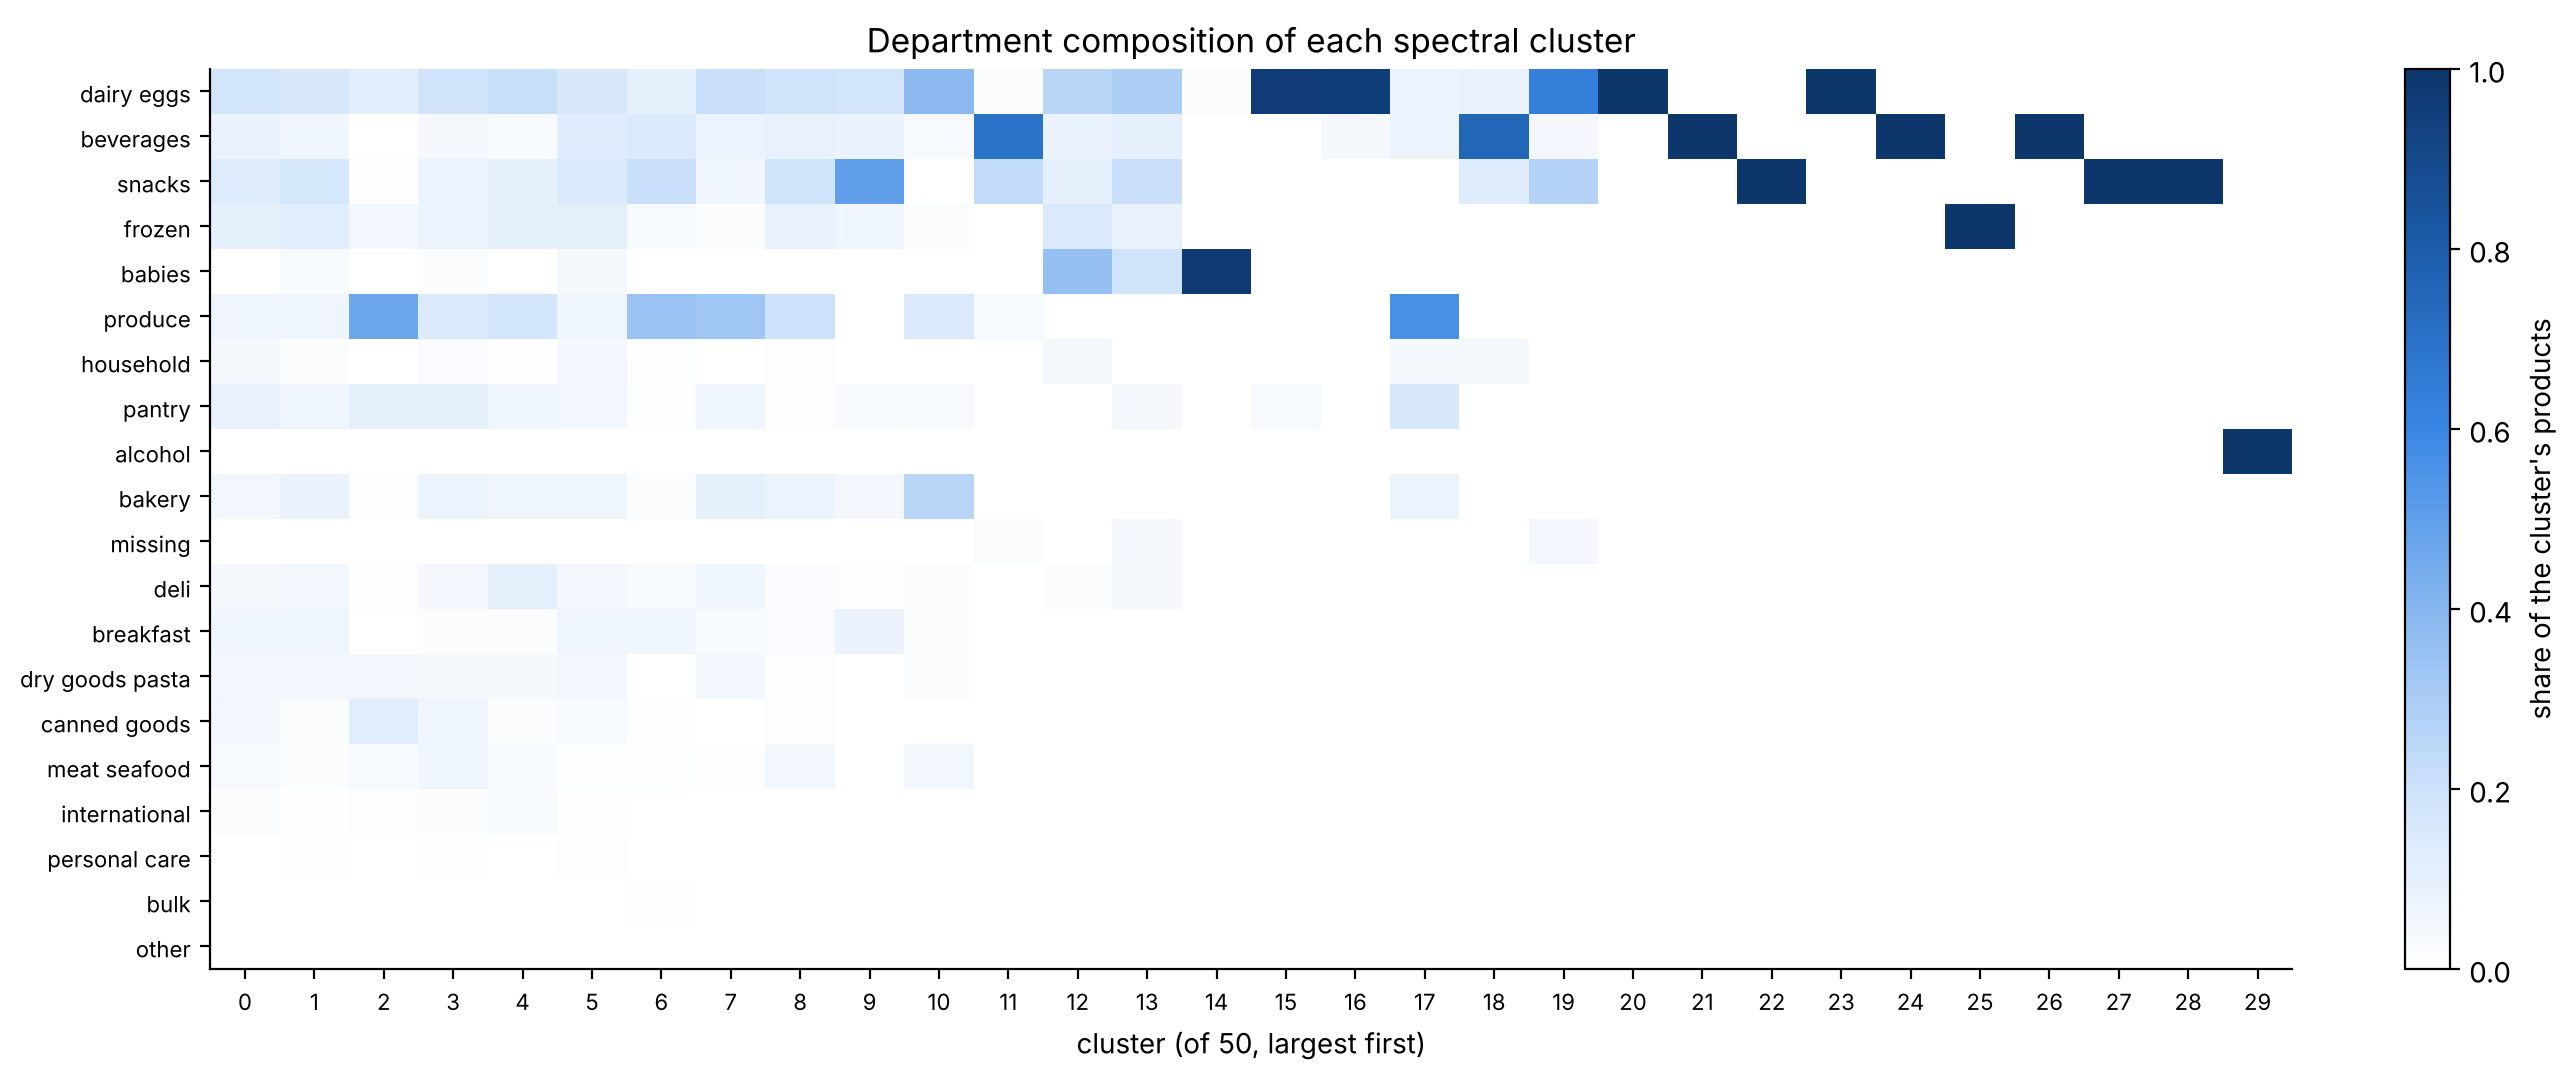

In [18]:
shown = 30
cross = pd.crosstab(pd.Series(dept, name="department"), pd.Series(labels, name="cluster"), normalize="columns")
cross = cross.loc[cross.sum(axis=1).sort_values(ascending=False).index, range(shown)]
fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(cross.to_numpy(), cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(cross)), cross.index, fontsize=8)
ax.set_xticks(range(shown), range(shown), fontsize=8)
ax.set(xlabel=f"cluster (of {K_FINAL}, largest first)", title="Department composition of each spectral cluster")
ax.grid(False)
fig.colorbar(im, ax=ax, label="share of the cluster's products", fraction=0.025)
fig.tight_layout()
fig.savefig(FIG_DIR / "spectral_clusters_vs_departments.png", dpi=150)

In [19]:
out = pd.DataFrame({"product_id": ids, "cluster": labels})
out.to_csv(DERIVED / f"spectral_clusters_k{K_FINAL}.csv", index=False)
print(f"saved {len(out):,} products with their cluster to data/derived/spectral_clusters_k{K_FINAL}.csv")

saved 3,634 products with their cluster to data/derived/spectral_clusters_k50.csv


## Conclusions

- **Correctness.** Our implementation reproduces the toy graph by hand (eigenvalues, Fiedler vector, the three triangles),
  agrees exactly with scikit-learn on the karate club for $k = 2, 3$, our modularity equals networkx's, and the sparse
  and dense eigen-solvers agree to $10^{-14}$.
- **The graph.** The 54,733 frequent pairs with lift above 1 connect 3,687 products. 21 tiny components are single
  brands' product lines (cat food, soy yogurt, kombucha); the remaining 3,634 products form one component.
- **Efficiency.** The 150 smallest eigenpairs take under a second with the sparse Lanczos solver against about 6 s for the
  dense one, and the gap grows with $n^3$; only the sparse solver scales to bigger graphs.
- **One eigenvector is not enough.** The lecture's sign split separates a single product (unnormalised Laplacian) or the
  9 wines and beers (normalised Laplacian): the graph has no balanced cut, and normalising by volume matters.
- **Design.** Log-lift weights with each product's 10 strongest partners give clusters with high modularity without one
  cluster absorbing a large share of the products. Raw lift looks better on modularity only by isolating niche pairs.
- **Number of clusters.** Modularity peaks at about 0.59 around $k = 50$. The eigengap gives no clear answer (many
  near-zero eigenvalues from loosely attached groups); its largest gap is at $k = 131$, close to the 134 aisles.
- **Methods.** Of the spectral variants, NJW (normalised Laplacian with unit-length rows) is best, and the row scaling is
  essential: the unnormalised version and scikit-learn (which scales the eigenvectors by $D^{-1/2}$ instead) leave
  most products in one giant cluster. Recursive bipartition with $L_{sym}$ comes close and is the most balanced, but is slower.
  Louvain reaches a higher modularity (0.69), which is expected since it maximises modularity directly; NJW with the same
  number of communities reaches 0.57.
- **Purchase behaviour vs. the store layout.** The clusters agree only weakly with the real categories (AMI about 0.14 for
  both departments and aisles, against about 0 for random labels). They do not recover the store's layout; they recover
  *what is bought together*: the purest clusters are product lines and shopping missions (one brand's Greek yogurt flavours,
  baby food, sparkling waters, kombucha, ice cream, and cooking basics such as garlic, onions, parsley and parmesan),
  while the large clusters mix departments around everyday staples such as bananas, avocados and milk.